# 01 — Data Exploration
## AI-Based Electricity Demand Prediction and Fair Load-Shedding Scheduler
**AL-2002 Artificial Intelligence Laboratory — Fall 2026 — FAST-NUCES Karachi (BDS-5A)**

> ⚠️ **All data in this project is SIMULATED.** It was generated by `dataset_generator.py` (seed 42) and is **not** real data from K-Electric or any other utility.

This notebook explores the four generated CSV files so we understand the data before building the Regression model, the CSP scheduler and Hill Climbing.
It only **reads** the files in `data/` — nothing is regenerated or modified.

| File | Meaning | Expected rows |
|---|---|---|
| `feeders.csv` | static feeder information and outage rules | 10 |
| `hourly_demand.csv` | demand per scenario × hour × feeder (Regression target: `actual_demand_mw`) | 12,000 |
| `hourly_supply.csv` | shared network supply per scenario × hour | 1,200 |
| `weather_time.csv` | simulated weather and time features | 1,200 |

## 1. Import libraries

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

## 2. Load the four CSV files
The notebook finds the project root automatically (it works whether VS Code starts it in the project folder or in a sub-folder).

In [2]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
print("Project root:", PROJECT_ROOT)

# keep_default_na=False: an empty 'protected_hours' cell means "no protected hours", not a missing value.
feeders = pd.read_csv(DATA_DIR / "feeders.csv", keep_default_na=False)
demand = pd.read_csv(DATA_DIR / "hourly_demand.csv")
supply = pd.read_csv(DATA_DIR / "hourly_supply.csv")
weather = pd.read_csv(DATA_DIR / "weather_time.csv")
tables = {"feeders": feeders, "hourly_demand": demand, "hourly_supply": supply, "weather_time": weather}
print("Loaded:", {name: len(df) for name, df in tables.items()})

Project root: /home/claude/Project
Loaded: {'feeders': 10, 'hourly_demand': 12000, 'hourly_supply': 1200, 'weather_time': 1200}


## 3. First five rows of each table

In [3]:
for name, df in tables.items():
    print(f"\n=== {name} ===")
    display(df.head())


=== feeders ===


,feeder_id,area,feeder_name,feeder_capacity_mw,priority,priority_weight,is_critical,critical_type,max_total_outage_hours,max_consecutive_outage_hours,protected_hours,base_demand_mw,demand_variation_pct
0,F001,North Karachi,North Karachi Hospital Feeder 001,16.0,5,5.0,True,Hospital,0,0,"00,01,02,03,04,05,06,07,08,09,10,11,12,13,14,1...",9.0,3.0
1,F002,North Karachi,North Karachi Industrial Feeder 002,36.0,3,2.0,False,Industrial,4,2,"09,10,11,12,13,14",20.0,5.0
2,F003,Gulshan,Gulshan Residential Feeder 003,28.0,3,2.0,False,Residential,5,2,,15.0,10.0
3,F004,Gulshan,Gulshan Commercial Feeder 004,32.0,4,3.0,False,Commercial,3,1,"11,12,13,14",17.0,8.0
4,F005,Saddar,Saddar Commercial Feeder 005,34.0,4,3.0,False,Commercial,3,1,"12,13,14,15",18.0,8.0



=== hourly_demand ===


,scenario_id,hour,time_label,feeder_id,area,day_type,season,temperature_c,humidity_pct,previous_hour_demand_mw,actual_demand_mw,demand_category,feeder_capacity_mw
0,S001,0,00:00,F001,North Karachi,Weekday,Summer,33.2,56.9,8.116,8.551,Medium,16.0
1,S001,0,00:00,F002,North Karachi,Weekday,Summer,33.2,56.9,17.118,18.239,Medium,36.0
2,S001,0,00:00,F003,Gulshan,Weekday,Summer,33.2,56.9,10.622,9.514,Low,28.0
3,S001,0,00:00,F004,Gulshan,Weekday,Summer,33.2,56.9,6.708,6.806,Low,32.0
4,S001,0,00:00,F005,Saddar,Weekday,Summer,33.2,56.9,7.164,7.628,Low,34.0



=== hourly_supply ===


,scenario_id,hour,time_label,available_supply_mw,reserve_mw,usable_supply_mw,total_demand_mw,shortage_mw,supply_status
0,S001,0,00:00,91.714,4.550,87.164,99.023,11.859,Shortage
1,S001,1,01:00,85.863,3.107,82.756,95.106,12.350,Shortage
2,S001,2,02:00,84.379,4.006,80.373,90.710,10.337,Shortage
3,S001,3,03:00,82.945,3.968,78.977,90.183,11.206,Shortage
4,S001,4,04:00,90.745,2.509,88.236,93.965,5.729,Tight



=== weather_time ===


,scenario_id,hour,time_label,day_type,day_of_week,season,temperature_c,humidity_pct,is_weekend,is_peak_hour,is_morning_peak,is_evening_peak
0,S001,0,00:00,Weekday,Monday,Summer,33.2,56.9,False,False,False,False
1,S001,1,01:00,Weekday,Monday,Summer,32.5,56.9,False,False,False,False
2,S001,2,02:00,Weekday,Monday,Summer,32.1,56.4,False,False,False,False
3,S001,3,03:00,Weekday,Monday,Summer,32.1,57.4,False,False,False,False
4,S001,4,04:00,Weekday,Monday,Summer,32.2,54.8,False,False,False,False


## 4. Shape and column names

In [4]:
for name, df in tables.items():
    print(f"{name}: {df.shape[0]} rows x {df.shape[1]} columns")
    print("   ", list(df.columns))

feeders: 10 rows x 13 columns
    ['feeder_id', 'area', 'feeder_name', 'feeder_capacity_mw', 'priority', 'priority_weight', 'is_critical', 'critical_type', 'max_total_outage_hours', 'max_consecutive_outage_hours', 'protected_hours', 'base_demand_mw', 'demand_variation_pct']
hourly_demand: 12000 rows x 13 columns
    ['scenario_id', 'hour', 'time_label', 'feeder_id', 'area', 'day_type', 'season', 'temperature_c', 'humidity_pct', 'previous_hour_demand_mw', 'actual_demand_mw', 'demand_category', 'feeder_capacity_mw']
hourly_supply: 1200 rows x 9 columns
    ['scenario_id', 'hour', 'time_label', 'available_supply_mw', 'reserve_mw', 'usable_supply_mw', 'total_demand_mw', 'shortage_mw', 'supply_status']
weather_time: 1200 rows x 12 columns
    ['scenario_id', 'hour', 'time_label', 'day_type', 'day_of_week', 'season', 'temperature_c', 'humidity_pct', 'is_weekend', 'is_peak_hour', 'is_morning_peak', 'is_evening_peak']


## 5. Data types and info

In [5]:
for name, df in tables.items():
    print(f"\n=== {name} ===")
    df.info()


=== feeders ===
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   feeder_id                     10 non-null     str    
 1   area                          10 non-null     str    
 2   feeder_name                   10 non-null     str    
 3   feeder_capacity_mw            10 non-null     float64
 4   priority                      10 non-null     int64  
 5   priority_weight               10 non-null     float64
 6   is_critical                   10 non-null     bool   
 7   critical_type                 10 non-null     str    
 8   max_total_outage_hours        10 non-null     int64  
 9   max_consecutive_outage_hours  10 non-null     int64  
 10  protected_hours               10 non-null     str    
 11  base_demand_mw                10 non-null     float64
 12  demand_variation_pct          10 non-null     float64
dtypes:

## 6. Descriptive statistics

In [6]:
display(feeders.describe())
display(demand[["temperature_c", "humidity_pct", "previous_hour_demand_mw", "actual_demand_mw"]].describe())
display(supply[["available_supply_mw", "reserve_mw", "usable_supply_mw", "total_demand_mw", "shortage_mw"]].describe())
display(weather[["temperature_c", "humidity_pct"]].describe())

,feeder_capacity_mw,priority,priority_weight,max_total_outage_hours,max_consecutive_outage_hours,base_demand_mw,demand_variation_pct
count,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
mean,28.400000,3.300000,2.500000,3.900000,1.500000,15.400000,7.700000
std,7.167829,0.948683,1.054093,1.791957,0.707107,3.864367,2.540779
min,16.000000,2.000000,1.500000,0.000000,0.000000,9.000000,3.000000
25%,23.500000,3.000000,2.000000,3.000000,1.000000,12.750000,5.750000
50%,29.000000,3.000000,2.000000,4.000000,2.000000,15.500000,8.000000
75%,33.500000,4.000000,3.000000,5.000000,2.000000,17.750000,10.000000
max,38.000000,5.000000,5.000000,6.000000,2.000000,21.000000,10.000000


,temperature_c,humidity_pct,previous_hour_demand_mw,actual_demand_mw
count,12000.000000,12000.000000,12000.000000,12000.000000
mean,29.380917,59.291583,13.296521,13.305381
std,6.626186,11.783014,5.601756,5.603136
min,15.300000,36.400000,3.395000,3.395000
25%,24.700000,50.800000,8.636750,8.704000
50%,30.600000,55.200000,12.643000,12.677000
75%,34.100000,71.900000,17.549000,17.609250
max,42.000000,88.100000,29.400000,29.400000


,available_supply_mw,reserve_mw,usable_supply_mw,total_demand_mw,shortage_mw
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,134.841702,4.695034,130.146668,133.053813,7.970917
std,36.678522,1.794063,35.398774,33.912047,10.960670
min,57.853000,1.342000,56.511000,68.113000,0.000000
25%,102.016250,3.338500,98.593250,97.065750,0.000000
50%,138.652500,4.417000,133.320500,145.557000,0.000000
75%,164.481000,5.839500,159.460500,160.343250,13.040000
max,214.073000,10.325000,207.730000,190.501000,52.514000


,temperature_c,humidity_pct
count,1200.000000,1200.000000
mean,29.380917,59.291583
std,6.628672,11.787435
min,15.300000,36.400000
25%,24.700000,50.800000
50%,30.600000,55.200000
75%,34.100000,71.900000
max,42.000000,88.100000


## 7. Missing values
`protected_hours` is an empty string for feeders without protected hours — that is intentional, not a missing value.

In [7]:
for name, df in tables.items():
    missing = df.isna().sum().sum()
    print(f"{name:15s} missing values: {missing}")
print("\nFeeders with no protected hours:", (feeders["protected_hours"] == "").sum())

feeders         missing values: 0
hourly_demand   missing values: 0
hourly_supply   missing values: 0
weather_time    missing values: 0

Feeders with no protected hours: 3


## 8. Duplicate records

In [8]:
print("feeders duplicate feeder_id        :", feeders["feeder_id"].duplicated().sum())
print("demand duplicate scenario-hour-feeder:", demand.duplicated(["scenario_id", "hour", "feeder_id"]).sum())
print("supply duplicate scenario-hour     :", supply.duplicated(["scenario_id", "hour"]).sum())
print("weather duplicate scenario-hour    :", weather.duplicated(["scenario_id", "hour"]).sum())

# Structure checks
print("\nScenarios:", demand["scenario_id"].nunique(), "| hours per scenario:", demand.groupby("scenario_id")["hour"].nunique().unique(),
      "| feeders per scenario-hour:", demand.groupby(["scenario_id", "hour"]).size().unique())

feeders duplicate feeder_id        : 0
demand duplicate scenario-hour-feeder: 0
supply duplicate scenario-hour     : 0
weather duplicate scenario-hour    : 0

Scenarios: 50 | hours per scenario: [24] | feeders per scenario-hour: [10]


## 9. Feeders and areas
Five areas, two feeders each. **F001 is the hospital feeder** and must always stay ON.

,feeder_id,area,critical_type,feeder_capacity_mw,base_demand_mw,priority,max_total_outage_hours,max_consecutive_outage_hours,protected_hours
0,F001,North Karachi,Hospital,16.0,9.0,5,0,0,"00,01,02,03,04,05,06,07,08,09,10,11,12,13,14,1..."
1,F002,North Karachi,Industrial,36.0,20.0,3,4,2,"09,10,11,12,13,14"
2,F003,Gulshan,Residential,28.0,15.0,3,5,2,
3,F004,Gulshan,Commercial,32.0,17.0,4,3,1,"11,12,13,14"
4,F005,Saddar,Commercial,34.0,18.0,4,3,1,"12,13,14,15"
5,F006,Saddar,Residential,22.0,12.0,2,6,2,
6,F007,Clifton,Residential,30.0,16.0,3,5,2,"20,21"
7,F008,Clifton,Commercial,28.0,15.0,3,4,2,"11,12,13"
8,F009,Malir,Industrial,38.0,21.0,4,3,1,"08,09,10,11,12,13,14,15"
9,F010,Malir,Residential,20.0,11.0,2,6,2,


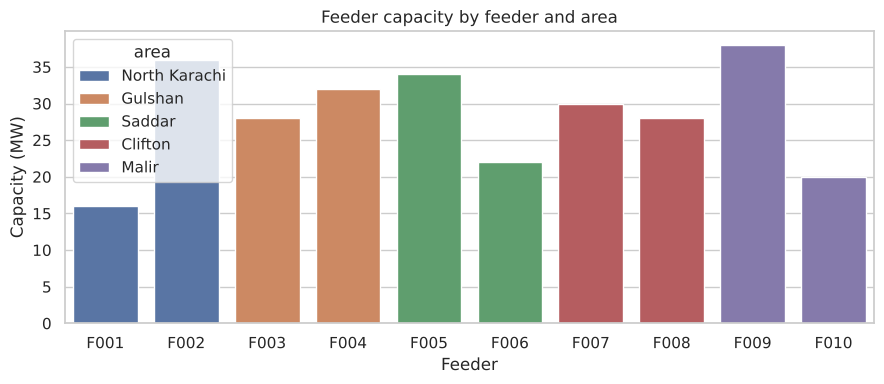

In [9]:
display(feeders[["feeder_id", "area", "critical_type", "feeder_capacity_mw", "base_demand_mw", "priority",
                 "max_total_outage_hours", "max_consecutive_outage_hours", "protected_hours"]])
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=feeders, x="feeder_id", y="feeder_capacity_mw", hue="area", dodge=False, ax=ax)
ax.set_title("Feeder capacity by feeder and area"); ax.set_ylabel("Capacity (MW)"); ax.set_xlabel("Feeder")
plt.tight_layout(); plt.show()

## 10. Demand pattern by hour
Residential feeders peak in the morning and evening, commercial feeders during working hours, industrial and hospital feeders are flatter.

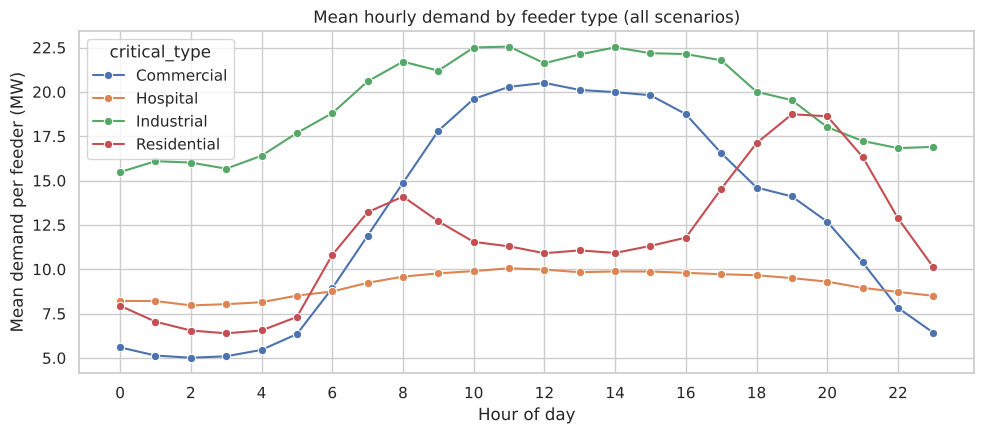

In [10]:
demand = demand.merge(feeders[["feeder_id", "critical_type"]], on="feeder_id")
by_hour = demand.groupby(["hour", "critical_type"])["actual_demand_mw"].mean().reset_index()
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=by_hour, x="hour", y="actual_demand_mw", hue="critical_type", marker="o", ax=ax)
ax.set_title("Mean hourly demand by feeder type (all scenarios)"); ax.set_xlabel("Hour of day"); ax.set_ylabel("Mean demand per feeder (MW)")
ax.set_xticks(range(0, 24, 2)); plt.tight_layout(); plt.show()

## 11. Demand pattern by feeder

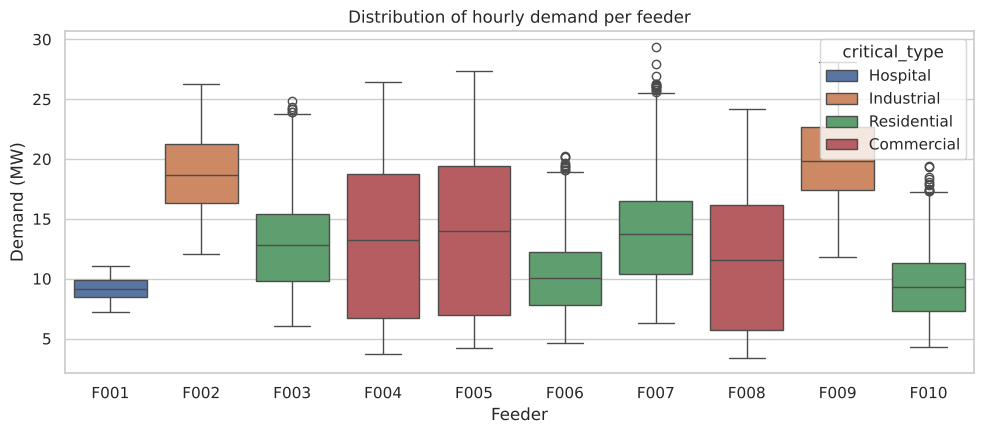

Demand category counts:


,rows
demand_category,
Low,3511
Medium,7018
High,1419
Peak,52


In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=demand, x="feeder_id", y="actual_demand_mw", hue="critical_type", dodge=False, ax=ax)
ax.set_title("Distribution of hourly demand per feeder"); ax.set_ylabel("Demand (MW)"); ax.set_xlabel("Feeder")
plt.tight_layout(); plt.show()

print("Demand category counts:")
display(demand["demand_category"].value_counts().reindex(["Low", "Medium", "High", "Peak"]).to_frame("rows"))

## 12. Day type and season effects on demand

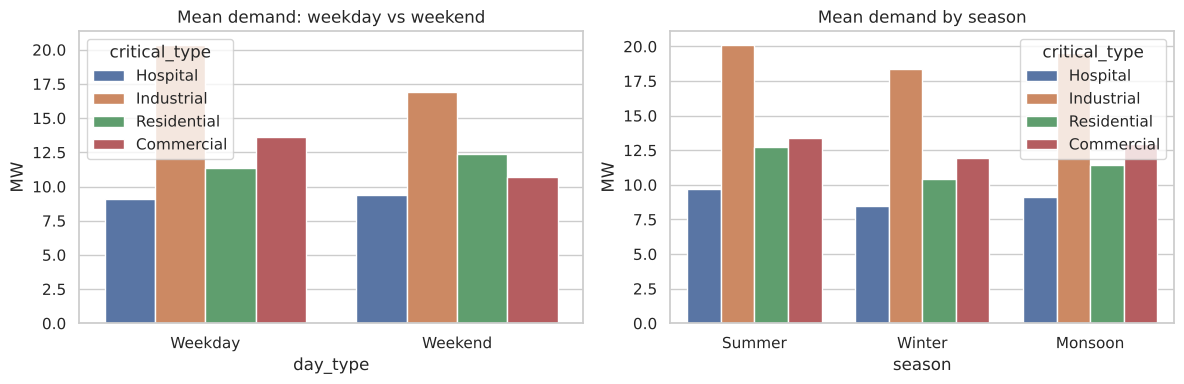

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=demand, x="day_type", y="actual_demand_mw", hue="critical_type", errorbar=None, ax=axes[0])
axes[0].set_title("Mean demand: weekday vs weekend"); axes[0].set_ylabel("MW")
sns.barplot(data=demand, x="season", y="actual_demand_mw", hue="critical_type", errorbar=None, ax=axes[1])
axes[1].set_title("Mean demand by season"); axes[1].set_ylabel("MW")
plt.tight_layout(); plt.show()

## 13. Supply vs total demand
Supply is **shared by the whole network** — one value per scenario-hour (it is not summed per feeder).

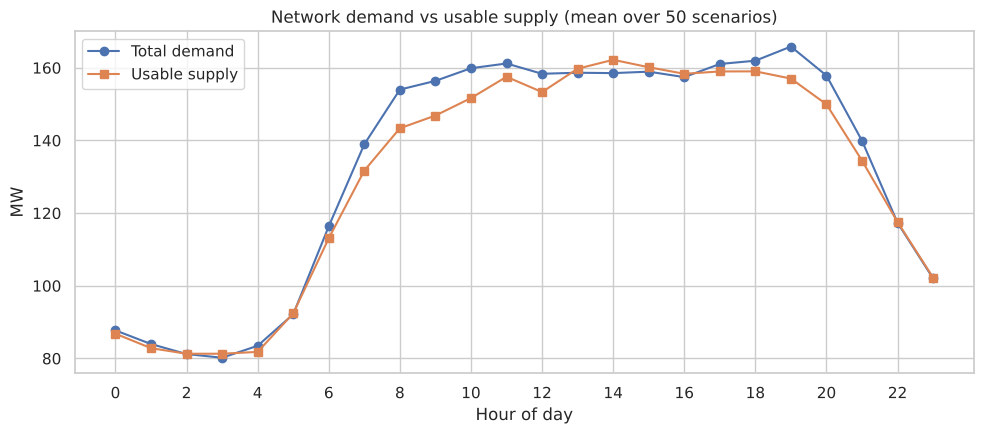

usable = available - reserve   : True
total_demand = sum of feeders  : True


In [13]:
mean_by_hour = supply.groupby("hour")[["total_demand_mw", "usable_supply_mw"]].mean()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(mean_by_hour.index, mean_by_hour["total_demand_mw"], marker="o", label="Total demand")
ax.plot(mean_by_hour.index, mean_by_hour["usable_supply_mw"], marker="s", label="Usable supply")
ax.set_title("Network demand vs usable supply (mean over 50 scenarios)")
ax.set_xlabel("Hour of day"); ax.set_ylabel("MW"); ax.set_xticks(range(0, 24, 2)); ax.legend()
plt.tight_layout(); plt.show()

# Arithmetic checks
print("usable = available - reserve   :", np.allclose(supply["usable_supply_mw"], supply["available_supply_mw"] - supply["reserve_mw"]))
sums = demand.groupby(["scenario_id", "hour"])["actual_demand_mw"].sum().reset_index(name="sum_demand")
check = supply.merge(sums, on=["scenario_id", "hour"])
print("total_demand = sum of feeders  :", np.allclose(check["total_demand_mw"], check["sum_demand"]))

## 14. Shortage distribution

               scenario-hours
supply_status                
Sufficient                629
Shortage                  313
Tight                     258

Hours with a shortage: 571 of 1200 (47.6%)


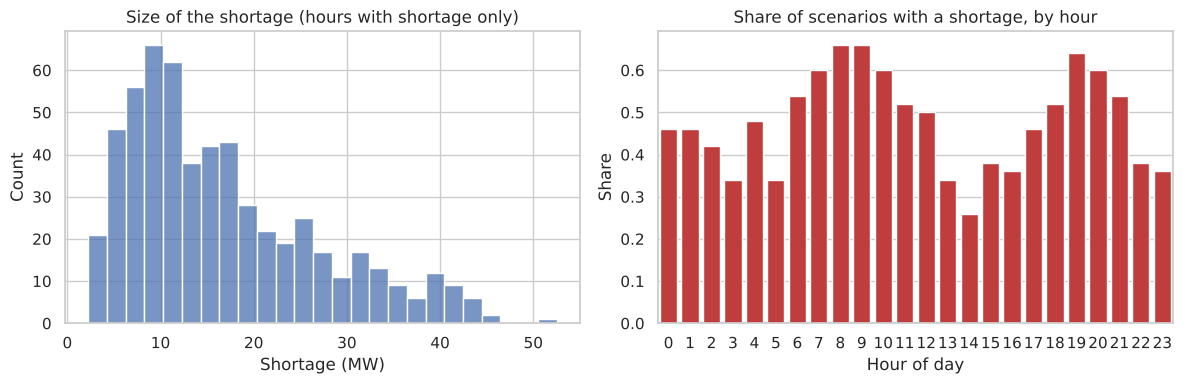

Shortage hours per scenario: min 0 | mean 11.4 | max 24


In [14]:
print(supply["supply_status"].value_counts().to_frame("scenario-hours"))
shortage_hours = supply[supply["shortage_mw"] > 0]
print(f"\nHours with a shortage: {len(shortage_hours)} of {len(supply)} ({100*len(shortage_hours)/len(supply):.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(shortage_hours["shortage_mw"], bins=25, ax=axes[0])
axes[0].set_title("Size of the shortage (hours with shortage only)"); axes[0].set_xlabel("Shortage (MW)")
sns.barplot(x=supply.groupby("hour")["shortage_mw"].apply(lambda s: (s > 0).mean()).index,
            y=supply.groupby("hour")["shortage_mw"].apply(lambda s: (s > 0).mean()).values, ax=axes[1], color="#d62728")
axes[1].set_title("Share of scenarios with a shortage, by hour"); axes[1].set_xlabel("Hour of day"); axes[1].set_ylabel("Share")
plt.tight_layout(); plt.show()

per_scenario = supply.groupby("scenario_id")["shortage_mw"].apply(lambda s: (s > 0).sum())
print("Shortage hours per scenario: min", per_scenario.min(), "| mean", round(per_scenario.mean(), 1), "| max", per_scenario.max())

## 15. Weather and time features (simulated)

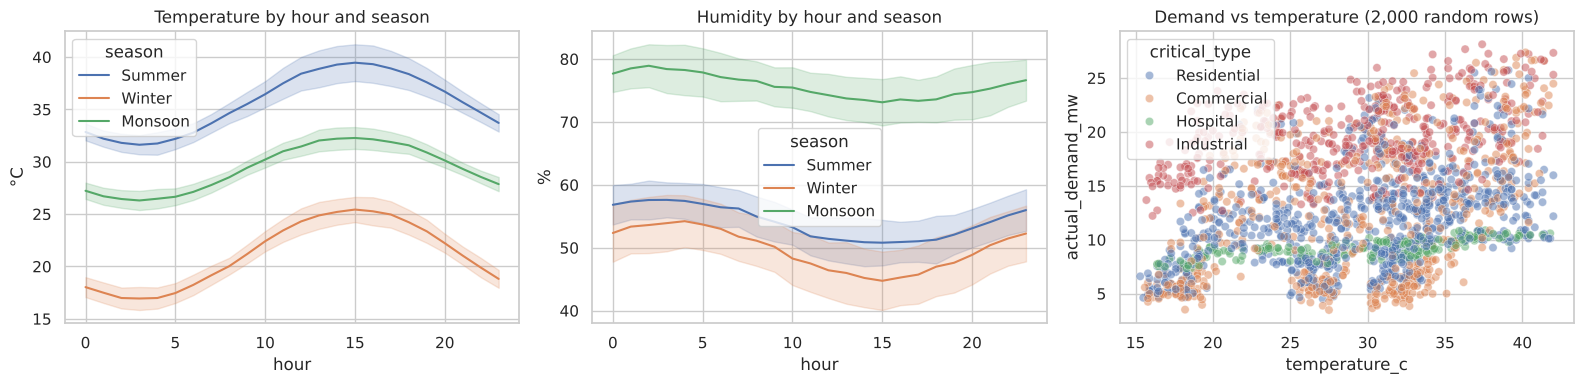

Scenarios per season  : {'Summer': 20, 'Winter': 15, 'Monsoon': 15}
Scenarios per day type: {'Weekday': 36, 'Weekend': 14}
Peak-hour flags       : morning [np.int64(6), np.int64(7), np.int64(8), np.int64(9)] | evening [np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21)]


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.lineplot(data=weather, x="hour", y="temperature_c", hue="season", errorbar="sd", ax=axes[0])
axes[0].set_title("Temperature by hour and season"); axes[0].set_ylabel("°C")
sns.lineplot(data=weather, x="hour", y="humidity_pct", hue="season", errorbar="sd", ax=axes[1])
axes[1].set_title("Humidity by hour and season"); axes[1].set_ylabel("%")
sns.scatterplot(data=demand.sample(2000, random_state=42), x="temperature_c", y="actual_demand_mw", hue="critical_type", alpha=0.5, ax=axes[2])
axes[2].set_title("Demand vs temperature (2,000 random rows)")
plt.tight_layout(); plt.show()

print("Scenarios per season  :", weather.drop_duplicates("scenario_id")["season"].value_counts().to_dict())
print("Scenarios per day type:", weather.drop_duplicates("scenario_id")["day_type"].value_counts().to_dict())
print("Peak-hour flags       : morning", sorted(weather.loc[weather.is_morning_peak, "hour"].unique()),
      "| evening", sorted(weather.loc[weather.is_evening_peak, "hour"].unique()))

## 16. Important observations

* The data is **simulated** and internally consistent: 10 feeders, 5 areas (2 feeders each), 50 scenarios × 24 hours, no missing values, no duplicates.
* Demand follows realistic patterns: low at night, morning and evening peaks for residential feeders, working-hours demand for commercial feeders, and a stable level for the hospital and industrial feeders. Higher temperature raises demand.
* `previous_hour_demand_mw` is strongly related to `actual_demand_mw`, so a **previous-hour baseline** is a strong competitor for the Regression model.
* Supply is shared by the network. A large share of scenario-hours has a shortage (mainly in peak hours), which creates meaningful work for the CSP scheduler.
* The hospital feeder **F001** must never be switched off. Other feeders have limits on total and consecutive outage hours and some protected hours.
* Because each feeder is either fully ON or fully OFF, switching off a feeder usually removes **more** demand than the exact shortage — Hill Climbing tries to reduce this over-shedding while keeping outage hours fair across areas.